# Decision Stump

**Professor:** Dr. Aldebaro Klautau

**Autora:** Elen Gomes

## Conceito

Uma Decision Stump é uma classificadora binária baseada numa característica (*feature*) para prever um alvo (*target*) com duas possíveis classes.

Algoritmicamente, a regra pode ser representada por:

$$
\hat{y}_n =
\begin{cases}
a, & \text{se } x_n > m,\\
b, & \text{caso contrário}.
\end{cases}
$$

Legenda:

- $x_n$: Valor da característica do exemplo $n$;
- $y_n$: Classe verdadeira do exemplo $n$;
- $\hat{y}_n$: Classe prevista pelo modelo para o exemplo $n$;
- $a$ e $b$: Classes que podem ser previstas pelo modelo;
- $m$: Limiar (*threshold*) aprendido durante o treinamento, utilizado para separar os exemplos em dois grupos.

Durante o treinamento, os valores de $x_n$ e os rótulos verdadeiros $y_n$ são conhecidos. O modelo aprende o limiar $m$ e as classes atribuídas aos dois ramos. Durante a predição, utiliza-se a regra aprendida para estimar $\hat{y}_n$, buscando que as previsões correspondam aos rótulos verdadeiros em exemplos não utilizados no treinamento.

Por exemplo, considere o seguinte conjunto de treinamento, no qual $y_n = 0$ representa um indivíduo que não pode dirigir e $y_n = 1$ representa um indivíduo que pode dirigir:

| Idade ($x_n$) | Classe verdadeira ($y_n$) |
|:---:|:---:|
| 16 | 0 |
| 17 | 0 |
| 19 | 1 |
| 20 | 1 |

Para esse conjunto de treinamento, um limiar de 18 anos separa perfeitamente as duas classes. Assim, a regra de classificação é:

$$
\hat{y}_n =
\begin{cases}
1, & \text{se idade} > 18,\\
0, & \text{caso contrário}.
\end{cases}
$$

Para as idades $[13, 18.5, 8, 35]$, o modelo produzirá as seguintes previsões:

$$
\hat{\mathbf{y}} = [0, 1, 0, 1]
$$

Portanto, a Decision Stump classificará indivíduos com mais de 18 anos na classe 1 e indivíduos com idade igual ou inferior a 18 anos na classe 0.

**Observação:** Este é um exemplo didático para explicar os componentes de uma Decision Stump. Embora a regra escolhida coincida com o critério de idade adotado neste exemplo, isso não garante sua validade legal ou prática visto que outros conjuntos de dados poderiam produzir limiares diferentes dos estabelecidos pela legislação vigente.

## Bibliotecas

In [10]:
import numpy as np #import numpy library
import matplotlib.pyplot as plt #import matplotlib library
from sklearn.tree import DecisionTreeClassifier, plot_tree #import DecisionTreeClassifier and plot_tree from sklearn.tree

## Visualização dos Dados

O código abaixo exibe os dados, que serão utilizados no decorrer deste arquivo, de treinamento no arquivo train_set.txt (descomente as linhas 1 e 10 e comente as linhas 2 e 11) ou teste no arquivo test_set.txt (descomente as linhas 2 e 11 e comente as linhas 1 e 10) com duas características (*length* e *weight*) e classes 0 e 1.

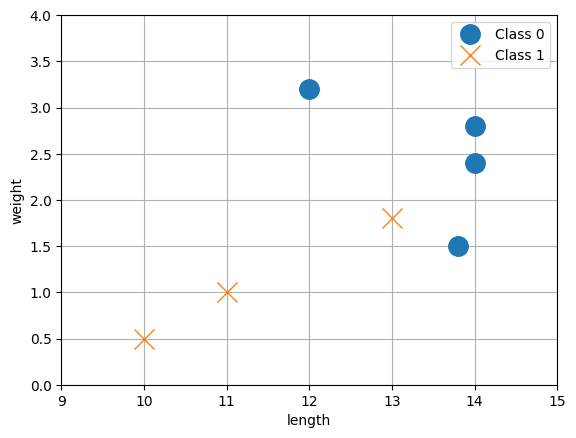

In [6]:
x = np.loadtxt('train_set.txt') #load from file to memory
# x = np.loadtxt('test_set.txt') #load from file to memory
indices0 = np.where(x[:, 2] == 0)[0] #find instances with class label == 0
indices1 = np.where(x[:, 2] == 1)[0] #find instances with class label == 1
x0 = x[indices0, :2] #class 0: only two features, without last column
x1 = x[indices1, :2] #class 1: only two features, without last column
plt.figure() #create a new figure
plt.plot(x0[:, 0], x0[:, 1], 'o', markersize=14, label='Class 0') #plot class 0
plt.plot(x1[:, 0], x1[:, 1], 'x', markersize=14, label='Class 1') #plot class 1
plt.axis([9, 15, 0, 4]) #resize the x and y axes
# plt.axis([8, 14, 0, 4]) #resize the x and y axes
plt.xlabel('length') #label the x-axis
plt.ylabel('weight') #label the y-axis
plt.legend() #show the legend
plt.grid() #show the grid
plt.show() #show the figure

## Regra de Decisão

Com base no conjunto de treino, visualmente, é possível concluir que uma possível regra de decisão é:

$$
\hat{y}_n =
\begin{cases}
0, & \text{se } {weight}_n > 1,\\
1, & \text{caso contrário}.
\end{cases}
$$

Que resulta em 75% de taxa de erro para o conjunto de teste test_set.txt.

In [7]:
x = np.loadtxt('test_set.txt') #load from file to memory
N, M = x.shape #N is the number of examples and M=3
numberOfErrors = 0 #count number of errors
for i in range(N): #go over all test set
    exampleFeatures = x[i, :2] #extract only features (discard label)
    #decision stump: if weight > 1 then class label is 0
    thisWeight = exampleFeatures[1] #choose feature
    if thisWeight > 1:
        classifierOutput = 0
    else:
        classifierOutput = 1
    if classifierOutput != x[i, 2]:
        numberOfErrors = numberOfErrors + 1 #update number of errors
print('Error rate (%) =', 100 * numberOfErrors / N)

Error rate (%) = 75.0


## Algoritmo de Treino e Teste

O algoritmo de treinamento de uma Decision Stump funciona da seguinte forma:

1. Iterar sobre cada atributo:
    1.1. Ordenar o conjunto de dados de acordo com os valores da característica selecionada;
    1.2. Considerar como limiar (threshold) a média aritmética entre os valores de cada par de exemplos consecutivos e calcular a respectiva taxa de erro de classificação.
2. Selecionar a melhor característica e limiar com base na menor taxa de erro de classificação.

A implementação abaixo se baseia na propriedade de que, em problemas de classificação binária, quando a taxa de erro de classificação é superior a 50%, a inversão dos rótulos previstos reduz a taxa de erro para abaixo de 50%.

Já o teste, é a implementação equivalente à descrita anteriormente, porém generalizado para qualquer regra de decisão de Decision Stump fornecida.

In [8]:
class DecisionStump:
    def __init__(self):
        self.featureIndex = None
        self.threshold = None
        self.greaterThanSign = None

    def predict(self, x):
        if self.featureIndex is None or self.threshold is None or self.greaterThanSign is None:
            raise ValueError("The decision stump has not been fitted yet.")
        if x.ndim != 2:
            raise ValueError("Input must be a 2D numpy array.")
        if x.shape[1] <= self.featureIndex:
            raise ValueError(
                f"Input must have at least {self.featureIndex + 1} features."
            )
        result = []
        for i in range(len(x)):
            if (x[i, self.featureIndex] > self.threshold and self.greaterThanSign) or \
            (x[i, self.featureIndex] < self.threshold and not self.greaterThanSign):
                result.append(0)
            else:
                result.append(1)
        return np.array(result)

    def fit(self, features, targets):
        N, M = features.shape #N: the number of examples, M: the number of features
        if M < 1:
            raise ValueError("Features must have at least one column.")
        if len(targets) != N:
            raise ValueError("Number of targets must match number of feature rows.")

        bestFeature = None
        bestThreshold = None
        greaterThanSign = True
        minErrorRate = float('inf') #initialize minimum error rate to infinity
        for i in range(M): #for each feature
            xSorted = features[features[:, i].argsort()] #sort the features based on x_i feature
            for j in range(N-1): #for each pair of consecutive examples
                threshold = (xSorted[j, i] + xSorted[j+1, i]) / 2 #calculate the threshold
                numberOfErrors = 0 #reset number of errors
                for k in range(N): #for each example
                    exampleFeatures = features[k, :M] #extract only features (discard label)
                    if exampleFeatures[i] > threshold: #decision stump: if feature > threshold then class label is 0
                        classifierOutput = 0
                    else:
                        classifierOutput = 1
                    if classifierOutput != targets[k]: #compare with true label
                        numberOfErrors += 1 #update number of errors
                errorRate = 100 * numberOfErrors / N
                #if the error rate is less than 50% then flip the decision stump
                if errorRate < 50:
                    greaterThan = True
                else:
                    greaterThan = False
                    errorRate = 100 - errorRate

                if errorRate < minErrorRate:
                    minErrorRate = errorRate
                    bestFeature = i
                    bestThreshold = threshold
                    greaterThanSign = greaterThan

        self.featureIndex = bestFeature
        self.threshold = bestThreshold
        self.greaterThanSign = greaterThanSign

## Implementação Customizada Vs. Árvore de Decisão do Sklearn

Partindo do pressuposto de que a Decision Stump é uma Árvore de Decisão de profundidade igual a 1, a implementação desenvolvida anteriormente deve ser equivalente à da biblioteca Sklearn com esta restrição, conforme demonstrado abaixo, com ambos atingindo a taxa de erro de 50%.

Sklearn Decision Tree Error rate (%) = 50.0
Custom Decision Stump Error rate (%) = 50.0


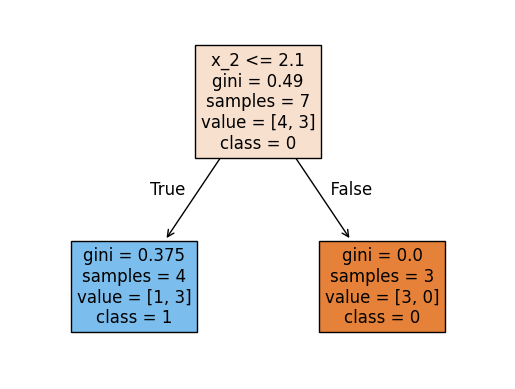

In [9]:
train = np.loadtxt('train_set.txt') #load from file to memory
test = np.loadtxt('test_set.txt') #load from file to memory

#initialize the sklearn decision tree and the custom decision stump
skModel = DecisionTreeClassifier(max_depth=1, random_state=0)
myModel = DecisionStump()

#fit the sklearn decision tree to the training data
skModel.fit(train[:, :2], train[:, 2]) #fit the sklearn decision tree to the training data
myModel.fit(train[:, :2], train[:, 2])

skTest = skModel.predict(test[:, :2]) #predict the class label of the test set using sklearn decision tree
myTest = myModel.predict(test[:, :2]) #predict the class label of the test set using custom decision stump

print('Sklearn Decision Tree Error rate (%) =', 100 * np.sum(skTest != test[:, 2]) / test.shape[0])
print('Custom Decision Stump Error rate (%) =', 100 * np.sum(myTest != test[:, 2]) / test.shape[0])

#print the Decision Tree
plt.figure()
plot_tree(skModel, filled=True, feature_names=["x_1", "x_2"], class_names=["0", "1"], fontsize=12)
plt.show()